# TUTORIAL <span style="color:orange;">***MASAÏ***</span><img width='64' style="float:right;margin:0 10px 0 20px;" src="images/masai.jpg" />

## Part 1. Basics of 1D processing and plotting

In the first part of this tutorial, 
we will learn how to open, process and plot a simple NMR spectrum acquired on a Bruker spectrometer.

#### Configuration
This line is not absolutely required, but strongly recommended on top of all notebooks.

In [5]:
from __future__ import division, print_function

#### Loading the <span style="color:orange;">***MASAÏ***</span> library

We import all from the MASAÏ api,

In [1]:
from masai.api import *

Populating the interactive namespace from numpy and matplotlib
matplotlib and numpy namespaces are available under the name 'plt' and 'np' respectively
matplotlib currently uses the 'nbagg' backend. 
	You can change it using e.g., plt.switch_backend('qt4agg') or %matplotlib inline
MASAI api loaded: version 0.2.2.3

The current directory is </Users/christian/Dropbox/PycharmProjects/masai/doc/tutorial>
MASAI root directory is </Users/christian/Dropbox/PycharmProjects/masai>


## Load a 1D fid

In [4]:
# get the doc for a plugin
Bruker()

Bruker

        Usage: source = Bruker(path, [processed=False], [lowmem=False])

        Parameters
        ----------
        path: str,
            path of the Bruker directory
        data_dir: str,
            main strorage directory, optional
        user: str, optional
            user name of the dataset
        name: str, optional
            name of the dataset
        expno: int, optional
            experiment number
        processed: bool, optioanl, default is False
            should we load already bruker processed files
        procno: int
            processing number

In [4]:
# specifications for the data to open
DATADIR = os.path.join(MASAI,'doc', 'tutorial', 'exemples')
user = 'user'
name = 'SPEC1D'
expno = 10

# load it
path = os.path.join(DATADIR, user,'nmr',name, str(expno))
source = Bruker(path)

Loaded FID


Alternative way for defining the file to load

In [5]:
source = Bruker(data_dir=DATADIR, user = 'user', name = 'SPEC1D', expno = 10)

Loaded FID


### Playing with the data!

In [7]:
source

***Bruker Source***
- path: /Users/christian/Dropbox/PycharmProjects/masai/doc/tutorial/exemples/user/nmr/SPEC1D/10
- datatype: 1D NMR FID
- pulse program: zg
- TD: 3120
- Limits: 0.00 to 38.987 ms

#### Preview of the data

In [8]:
source = Bruker(data_dir=DATADIR, user = 'user', name = 'SPEC1D', expno = 10)
source.data

Loaded FID


,0.0,0.0125,0.025,0.0375,0.05,0.0625,0.075,0.0875,0.1,0.1125,...,38.875,38.8875,38.9,38.9125,38.925,38.9375,38.95,38.9625,38.975,38.9875
0,(0.0438457013222+0.0958451776777j),(0.189612967304+0.981858911774j),(0.0664117722341+0.987157227243j),(-0.0177066920217+0.84325168518j),(-0.0873770891702+0.764192292965j),(-0.134166914513+0.672402582499j),(-0.180061543172+0.609856050161j),(-0.215138320422+0.538694128982j),(-0.248013151211+0.486111589302j),(-0.276721099306+0.421219879914j),...,(6.61218961942e-05+0.000996099544078j),(-0.000459078557101-9.02557145665e-06j),(0.00113357142521-9.76957985488e-05j),(-0.000617893046367-0.000827728358188j),(0.00146839772963-0.000659810836483j),(0.000347131440724-0.000164026755019j),(9.44220342009e-05+0.00107896216459j),(-0.000414012345799-0.000620011207108j),(0.00183363089753+0.000524630857486j),(-0.00148542654328-0.000604965150367j)


In [ ]:
source.real

In [ ]:
source.imag

#### We can access any attributes in the parameter's dictionary

In [ ]:
print('All P:', source.par.P)
print('P2:', source.par.P[2])
print('DE:', source.par.DE)

## Plot a 1D fid

In [8]:
# get the doc
Plot1d()

<IPython.core.display.Javascript object>


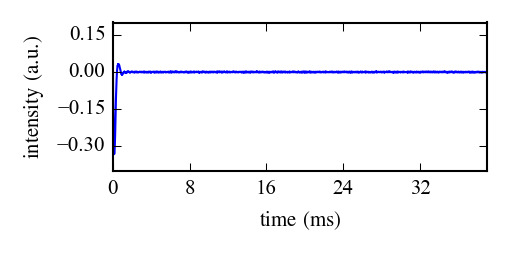

In [9]:
p = Plot1d(source)  # basic default plot

#### We can change some of the plot settings

<IPython.core.display.Javascript object>


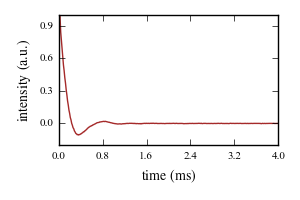

In [10]:
p = Plot1d(source, imag=True,
       figsize=(3.0,2.0), dpi=100, fontsize=8, xlim=(0, 4), c='brown')

#### We can overlay several plots using the ***hold*** keywords

<IPython.core.display.Javascript object>


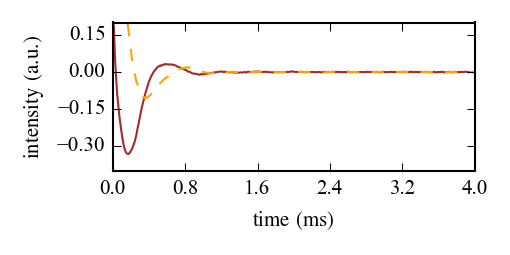

In [11]:
p = Plot1d(source, hold=True, color='brown')
p = Plot1d(source, axe=p.axe, imag=True, xlim=(0,4), color='orange', ls='--')  
                # we pass a reference to the previous axe (a)

#### We can add other objects to the plot

<IPython.core.display.Javascript object>


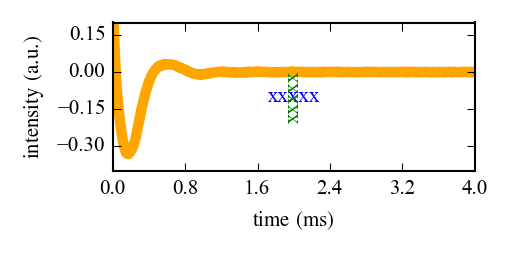

In [12]:
p = Plot1d(source, color='orange', ls='-', lw='5', alpha='.4', xlim=(0,4), 
           commands = ["text(2.0, -0.1, 'xxxxx', ha='center', va='center', color='b' )",
                       "text(2.0, -0.1, 'xxxxx', ha='center', va='center', color='g', rotation=90 )",
                      ])

#### To change the default labels

<IPython.core.display.Javascript object>


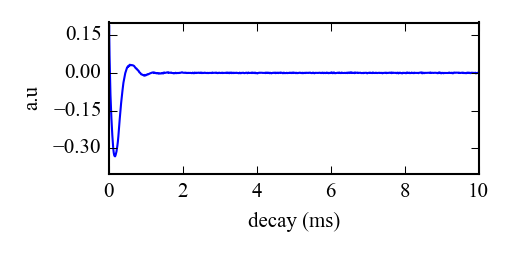

In [13]:
p = Plot1d(source, xlabel='decay (ms)', ylabel='a.u', xlim=(0,10))

#### To get help about plotting

In [14]:
Plot1d()

## Process a fid

In [15]:
# get the doc
Process()

Process
        Process a source

        Parameters
        ----------
        fd: source (such as NMR or IR source)
        transforms: str
            line(s) of commands among: em, zf, ft, pk, ab
            type Process(<command_name>) to get help on individual command

In [16]:
# get help on a command
Process('pk')

usage: 
    pk [-h] [--auto] [--fit_phc1] [--ediff EDIFF]
                           [--gamma GAMMA] [--select {standard,max,cols}]
                           [--threshold THRESHOLD] [--mode MODE]
                           [--optmode {simplex,hopping}]
                           [--bound_phc0 BOUND_PHC0] [--bound_phc1 BOUND_PHC1]
                           [--verbose]
                           [phases [phases ...]]
    

PK processing.

positional arguments:
  phases                zero and first order phase

optional arguments:
  -h, --help            show this help message and exit
  --pivot PIVOT, -pv PIVOT
                        pivot position in spectral units
  --shifted SHIFTED     position of the top in units of time
  --exp, -ex            perform an exponential phase correction
  --auto, -a            set to automatic phase mode
  --fit_phc1, -u1       use phc1 in automatic phasing
  --ediff EDIFF, -ef EDIFF
                        order of the derivative for entropy calcu

Process
        Process a source

        Parameters
        ----------
        fd: source (such as NMR or IR source)
        transforms: str
            line(s) of commands among: em, zf, ft, pk, ab
            type Process(<command_name>) to get help on individual command

Loaded FID
Exponential apodization lb:50.00
Zero-filling to si:4096
Fourier transform with si:4096
Phasing phc0:-178.00, phc1:-10.00


<IPython.core.display.Javascript object>


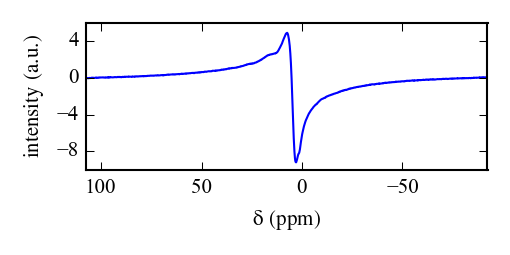

In [17]:
source = Bruker(path) 
Process(source, transform='em 50; zf 0; ft; pk -178 -10')
p = Plot1d(source)

#### Clipping and automatic phasing

Loaded FID
Exponential apodization lb:50.00
Zero-filling to si:8192
Fourier transform with si:8192
clipping along axis -1
Auto-phasing :  phc0 = -69.490, phc1(not optimized) = -10.000


<IPython.core.display.Javascript object>


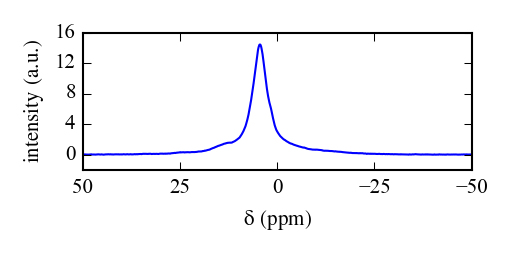

In [18]:
source = Bruker(path)  # reset to original data
Process(source, transform="em 50; zf 1; ft") # 1 zerofilling
Process(source, "cl -50 50")
Process(source, "pk --auto")
ax = Plot1d(source)

#### Use also phc1 for automatic phasing

Loaded FID
Exponential apodization lb:50.00
Zero-filling to si:8192
Fourier transform with si:8192
clipping along axis -1
Auto-phasing :  phc0 = -71.683, phc1 = -32.270


<IPython.core.display.Javascript object>


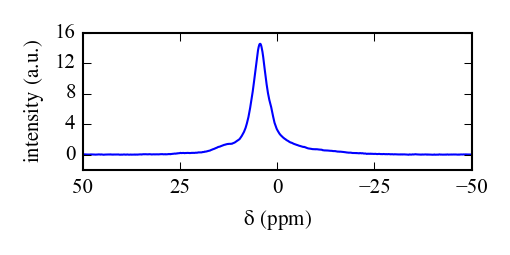

In [19]:
source = Bruker(path)  # reset to original data
Process(source, transform="em 50; zf 1; ft") # 1 zerofilling
Process(source, "cl -50 50")
Process(source, "pk --auto --fit_phc1 --bound_phc1 180 --pivot 4.5")
a = Plot1d(source) #, xlim=(30,-10))

#### Automatic baseline correction

<IPython.core.display.Javascript object>


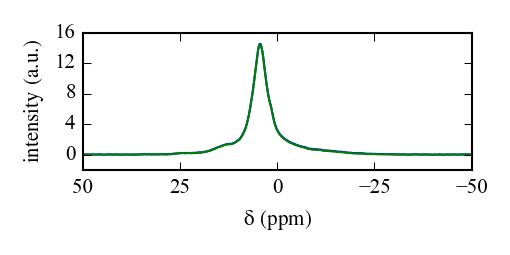

baseline correction mode:poly


In [20]:
p = Plot1d(source, hold=True)
Process(source, "ab --mode poly")
Plot1d(source, axe=p.axe)

#### Show for baseline correction

Loaded FID
Exponential apodization lb:50.00
Zero-filling to si:8192
Fourier transform with si:8192
Auto-phasing :  phc0 = -74.505, phc1 = 103.853


<IPython.core.display.Javascript object>


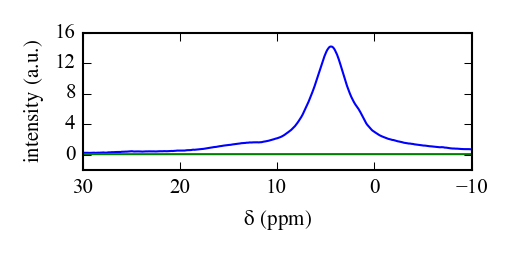

baseline correction mode:poly


In [21]:
source = Bruker(path)  # reset to original data
Process(source, transform="em 50; zf 1; ft; pk --auto --fit_phc1 --bound_phc1 360 --pivot 4.5")
p = Plot1d(source, hold=True)
Process(source, "ab --mode poly")
p = Plot1d(source.par.baseline, axe=p.axe, xlim=(30,-10), reverse=True)

#### To get help on Process or process commands

In [22]:
Process()

Process
        Process a source

        Parameters
        ----------
        fd: source (such as NMR or IR source)
        transforms: str
            line(s) of commands among: em, zf, ft, pk, ab
            type Process(<command_name>) to get help on individual command

In [23]:
Process("ft")

usage: ft [--si [SI]] [--tdeff [TDEFF]]

FT processing

optional arguments:
  -h, --help       show this help message and exit
  --si [SI]        size of fourier transform
  --tdeff [TDEFF]  size of fourier transform


Process
        Process a source

        Parameters
        ----------
        fd: source (such as NMR or IR source)
        transforms: str
            line(s) of commands among: em, zf, ft, pk, ab
            type Process(<command_name>) to get help on individual command

### Saving the figure

In [25]:
FIGDIR = os.path.join(MASAI,'doc', 'tutorial', 'figures')
filename = os.path.join(FIGDIR, 'spec1d.png')
p.savefig(filename)

Back to the main [Index](Index.ipynb)